# Asynchronous acoustic geometry: measurements → joint inverse → physical targets

## Problem

Ten unsynchronized microphones observe fourteen real sound emissions. Recover their **24 physical xyz positions**, estimating sensor offsets and drifts as nuisance quantities. The geometry comes from observations, not a supplied target or surveyed initializer. Independent surveyed xyz are used only for review after fitting. Zero clock placeholders in the original arrays are **not clock ground truth**.

## Data

The complete selected real acquisition contains 130 successive-event delays, 126 inter-microphone delays and 39 source-motion components. These are author-processed real audio and independent odometry with known two-plane height settings. Raw audio is not bundled. The frame is fixed by the first three observed motion positions. The original and fresh results below refer to these exact observations; no synthetic replacement or target-quality filter is used.

In [1]:
from pathlib import Path
import os,sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').is_file()
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import review_figures
data=load_data(ROOT/'data/raw_data.npz')
print({key:dict(shape=value.shape,unit='metres' if key=='displacement' else 'seconds') for key,value in data.items()})


{'tdoa_successive': {'shape': (13, 10), 'unit': 'seconds'}, 'tdoa_between': {'shape': (9, 14), 'unit': 'seconds'}, 'emission_intervals': {'shape': (14,), 'unit': 'seconds'}, 'displacement': {'shape': (13, 3), 'unit': 'metres'}}


## Physics

Let $m_i$ and $s_j$ be microphone and source vectors in metres, $c=340$ m/s, $d_{ij}=\lVert m_i-s_j\rVert_2$, $\tau_i$ an offset in seconds and $\delta_i$ a dimensionless fractional clock drift. Cumulative observed emission time is $t_j$. For successive and between-sensor observations, the predicted delays are

$$a_{ij}=(d_{i,j+1}-d_{ij})/c+(1+\delta_i)(t_{j+1}-t_j),\qquad b_{ij}=(d_{ij}-d_{0j})/c+\tau_i+(\delta_i-\delta_0)t_j.$$

Measured source displacement is predicted by $s_{j+1}-s_j$. This is a first-order clock approximation with direct-path Euclidean propagation. The first sensor offset is fixed to zero; its drift remains unknown. The source-coordinate gauge removes six rigid-motion freedoms. No post-fit rotation, translation or scale fit is allowed. Timing and motion have different units, so they are weighted separately.

## Method

The cleaned modules explicitly implement all distance, clock and displacement equations, their 295-by-85 analytic Jacobian and undamped Gauss–Newton updates. If residual vector is $r$, Jacobian is $J$ and diagonal nominal covariance is $W$, the objective is $F=\tfrac12 r^{\mathsf T}W^{-1}r$. The update solves $(J^{\mathsf T}W^{-1}J)\Delta=-J^{\mathsf T}W^{-1}r$. The source's left-to-right solve arithmetic, pre-update objective stop and mixed-unit step norm are preserved. Nominal 100 µs/1 cm weights are not calibrated instrument noise. Thirty independent uniform spatial starts use zero initial clocks; selection uses the smallest converged **observed** objective. The source's GT-based retry filter is excluded. A portable 100-iteration guard replaces a hardware-specific wall-time guard; accepted paths terminate by native numerical criteria.

The next cell **actively reconstructs the complete observations three times**: primary joint fit, an independent start library, and a deliberately incorrect zero-clock hypothesis. This ablation is not the paper's TDOA-M method. No archived reconstruction is returned as fresh.

In [2]:
runs={}
for label,options in [('fresh_joint',{}),('fresh_independent',{'seed':20261030}),('fresh_zero_clock',{'fit_clocks':False})]:
    start=time.perf_counter();result,diagnostics=reconstruct(data,**options)
    runs[label]=(result,diagnostics)
    print(label,json.dumps(dict(runtime_s=time.perf_counter()-start,observed_objective=diagnostics['cost'],selected_start=diagnostics['selected_start'],successful_starts=diagnostics['successful_starts'])))
result,diagnostics=runs['fresh_joint']
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',**result)
spec=importlib.util.spec_from_file_location('independent_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(ROOT/'output/reconstruction.npz')
assert report['passed'],report
print(json.dumps(report,indent=2))


fresh_joint {"runtime_s": 0.4946127999573946, "observed_objective": 201.6539697301266, "selected_start": 6, "successful_starts": 20}


fresh_independent {"runtime_s": 0.5048368000425398, "observed_objective": 201.6539403862906, "selected_start": 15, "successful_starts": 17}


fresh_zero_clock {"runtime_s": 3.197609900031239, "observed_objective": 2722.096116348786, "selected_start": 14, "successful_starts": 4}
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "microphone_ncc": 0.9595902583302564,
    "microphone_nrmse": 0.11810168463970996,
    "source_ncc": 0.9918537367301137,
    "source_nrmse": 0.04305363755707131,
    "timing_rms_seconds": 0.00010597671358637706,
    "odometry_rms_m": 0.017230913305371083
  },
  "thresholds": {
    "microphone_ncc": {
      "comparison": ">=",
      "boundary": 0.863552264032116
    },
    "microphone_nrmse": {
      "comparison": "<=",
      "boundary": 0.13012580258507822
    },
    "source_ncc": {
      "comparison": ">=",
      "boundary": 0.8926638020257446
    },
    "source_nrmse": {
      "comparison": "<=",
      "boundary": 0.04737395414762969
    },
    "timing_rms_seconds": {
      "comparison": "<=",
      "boundary": 0.00011657438494506271
    },
    "odometry_rms_m": {
      "comparison": "<=",
 

## Results

The actual surveyed positions below are independent reference measurements. The identified original joint outputs are from this task's independent Octave runs, not paper-reported numbers. The original TDOA-M comparator additionally uses a surveyed microphone coordinate frame: it is explicitly **privileged**, so only frame-invariant pairwise errors are shown, and no fair equal-information advantage is claimed. Source clock estimates have no measured ground truth.

Metric conventions are uncentered cosine and reference-dynamic-range coordinate NRMSE for each physical group, with all observed timing and motion constraints also checked. Clock nuisance fitting in the Judge uses only submitted geometry and public observations. The tables retain machine precision; figures round annotations for readability.

{
  "reproduced_original": {
    "microphone_ncc": 0.9595902583302607,
    "microphone_nrmse": 0.11810168463971041,
    "source_ncc": 0.991853736730127,
    "source_nrmse": 0.04305363755703929,
    "timing_rms_seconds": 0.00010597671358642064,
    "odometry_rms_m": 0.017230913305363076
  },
  "reproduced_original_independent": {
    "microphone_ncc": 0.9595025155912401,
    "microphone_nrmse": 0.11829618416825291,
    "source_ncc": 0.9918486689174939,
    "source_nrmse": 0.043067231043299715,
    "timing_rms_seconds": 0.00010595849618248322,
    "odometry_rms_m": 0.017238286550392508
  },
  "fresh_joint": {
    "microphone_ncc": 0.9595902583302564,
    "microphone_nrmse": 0.11810168463970996,
    "source_ncc": 0.9918537367301137,
    "source_nrmse": 0.04305363755707131,
    "timing_rms_seconds": 0.00010597671358637706,
    "odometry_rms_m": 0.017230913305371083
  },
  "fresh_independent": {
    "microphone_ncc": 0.9595815597647717,
    "microphone_nrmse": 0.11812941953567302,
    "sour

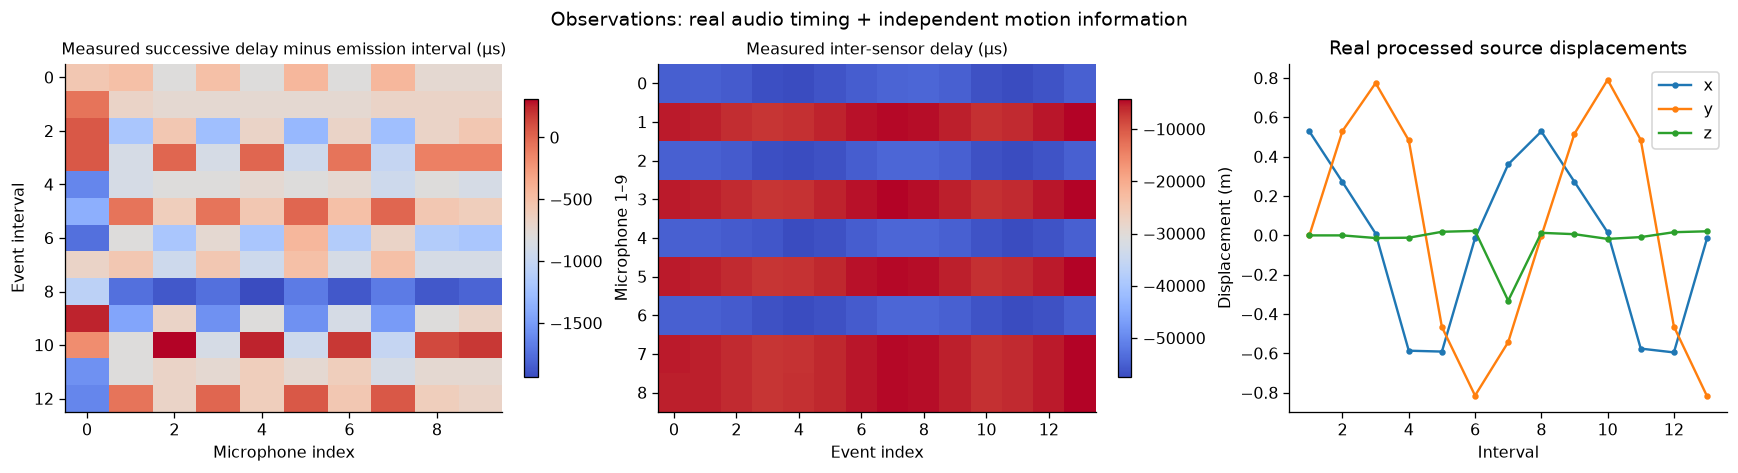

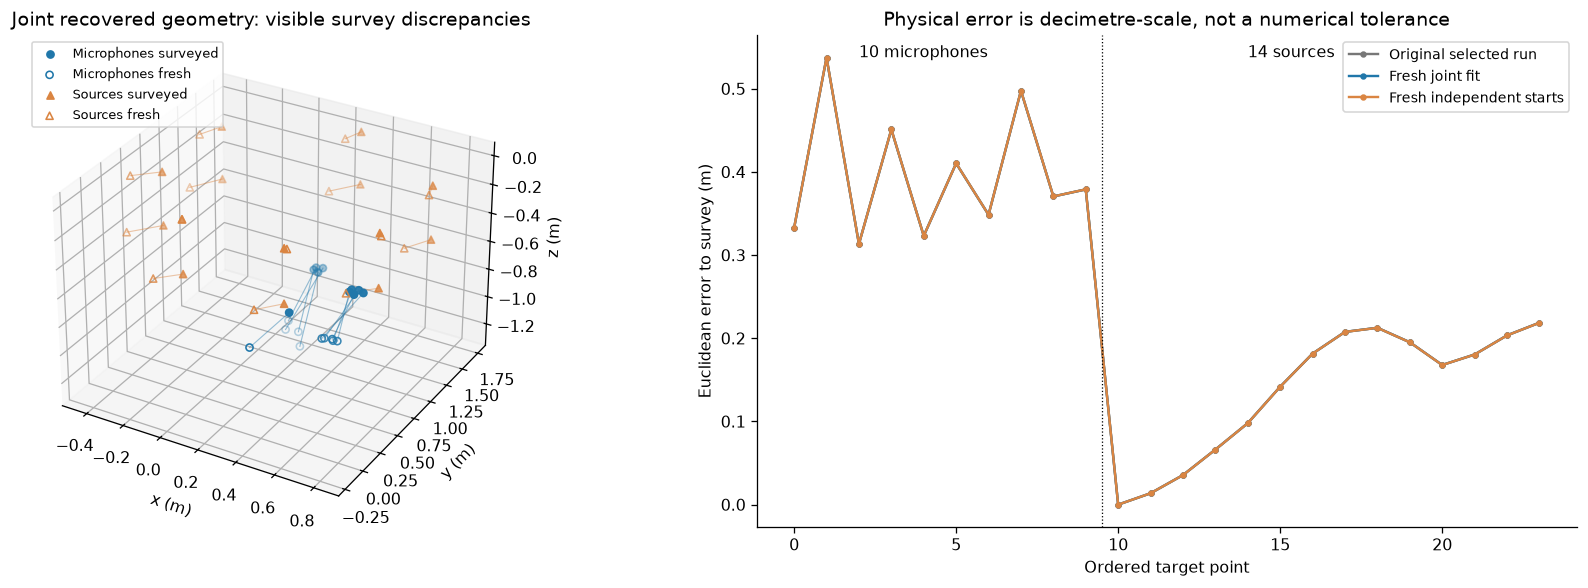

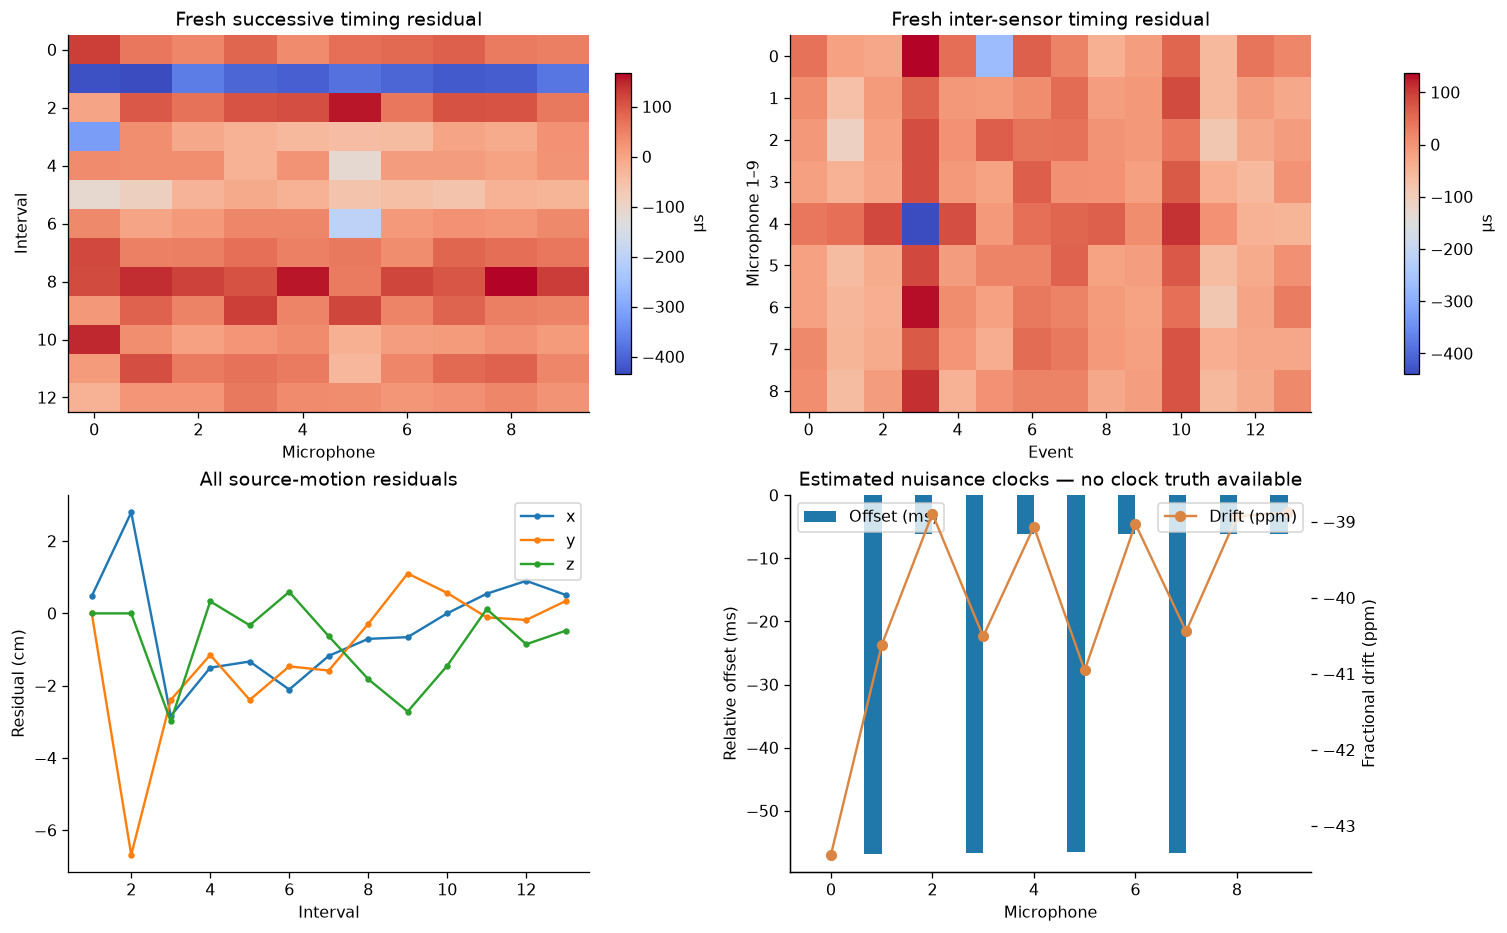

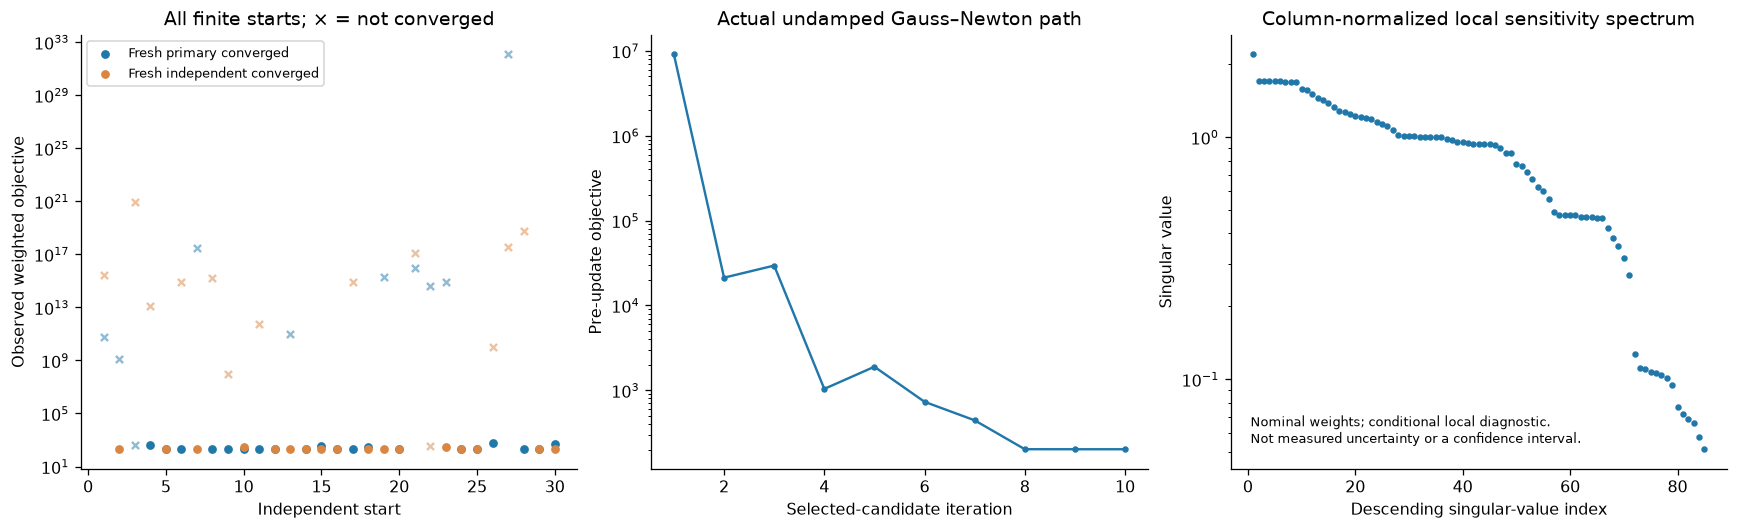

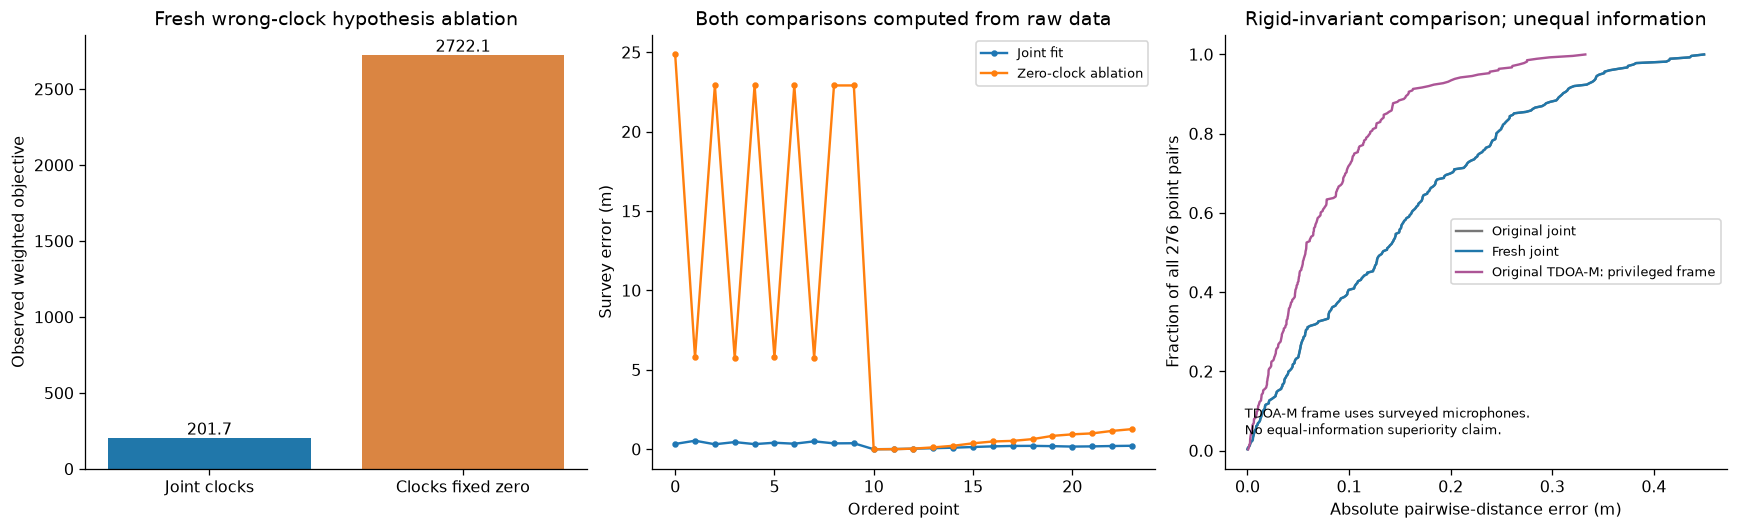

In [3]:
with np.load(ROOT/'evaluation/ground_truth.npz',allow_pickle=False) as z: truth=z['reconstruction'][0].copy()
with np.load(ROOT/'notebooks/reference_outputs/upstream_original.npz',allow_pickle=False) as z: upstream={k:z[k].copy() for k in z.files}
with np.load(ROOT/'notebooks/reference_outputs/upstream_privileged_comparator.npz',allow_pickle=False) as z: privileged={k:z[k].copy() for k in z.files}
rows={}
raw={k:v[None] for k,v in data.items()}
for label,points in [('reproduced_original',upstream['primary'][:,:3]),('reproduced_original_independent',upstream['repeat'][:,:3]),*[(key,value[0]['reconstruction'][0]) for key,value in runs.items()]]:
    rows[label]=judge.score(points,truth,raw)
print(json.dumps(rows,indent=2))
figures=review_figures(data,result,diagnostics,truth,upstream,*runs['fresh_independent'],*runs['fresh_zero_clock'],privileged)
for number,fig in enumerate(figures,1):
    if os.environ.get('IMAGING_REVIEW_EXPORT_DIR'):
        export=Path(os.environ['IMAGING_REVIEW_EXPORT_DIR']);export.mkdir(parents=True,exist_ok=True)
        fig.savefig(export/f'figure_{number:02d}.png',dpi=150)
    display(fig)
    plt.close(fig)


## Conclusion

The fresh code reconstructs all selected sensor and source positions from the full real timing/motion observations while fitting unknown sensor clocks. Agreement with the original code establishes method extraction; independent survey discrepancies establish a different, physical accuracy question. The latter is visibly on the decimetre scale, not equal to the millimetre parity tolerance. Several starts fail or converge differently, illustrating nonconvexity rather than warranting a hidden target-based selection.

The zero-clock comparison tests a deliberately wrong physical assumption using actual fresh results. The privileged original comparator is useful historical context but receives different information. Column-normalized sensitivity is a local conditional diagnostic, not a confidence interval, and the nominal weights are not certified noise variances. Direct-path and small-drift assumptions, limited geometry, processed timing and one bound real configuration limit generalization.

Reference: Zhang et al., *Asynchronous Microphone Array Calibration Using Hybrid TDOA Information*, arXiv:2403.05791v1. Method details, source revision, frozen parity cases, actual commands and explicit adaptations are recorded in the maintainer validation record.